# EE-commerce Sales Analysis
## Projekt Overview 
This projekt analyzes e-commerce sales data to evaluate business performance, identify top-performing product categories and cities, and detect unusually revenue records.
## Objectives 
- Calculate key business performance indicators.
- Analyze revenue by product category and city.
- Identify the top three categories by revenue.
- Visualize sales performance using charts. 
- Detect unusuall revenue records.
- Provide actionable business recommendations. 

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path 

print("libraries loaded successfully!")

libraries loaded successfully!


In [10]:
from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt


csv_path = next(
    (p for p in[
        Path("Data/ecommerce_sales.csv"),
        Path("data/ecommerce_sales.csv"),
        Path("ecommerce_sales.csv"), 
    ]
    
    if p.exists()),
    None
    )

if csv_path is None:
    raise FileNotFoundError("csv file not found!")

df = pd.read_csv(csv_path)
print("Datsset loaded successfully!")
print("Dataset shape: ", df.shape)
print("Columns: ", df.columns.tolist())

display(df.head())



FileNotFoundError: csv file not found!

In [45]:
# Calculate key performanceindicators(KPIs)
total_revenue = df["revenue"].sum()
total_units = df["units"].sum()
total_orders = df["order_id"].unique()
average_order_value = total_revenue/total_orders

print("Total Revenue: ", round(total_revenue, 2))
print("Total sold units: ", total_units)
print("Total Orders: ", total_orders)
print("Average order value: ", average_order_value)

Total Revenue:  3502767.23
Total sold units:  7463
Total Orders:  [100000 100001 100002 ... 102497 102498 102499]
Average order value:  [35.0276723  35.02732203 35.02697176 ... 34.17433905 34.17400564
 34.17367223]


In [46]:
#Revenue by category
revenue_by_category = df.groupby("category")["revenue"].sum()
revenue_by_category = revenue_by_category.sort_values(ascending=False)

print("Revenue by category: ")
display(revenue_by_category)


Revenue by category: 


category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Home            511070.87
Beauty          163053.97
Toys            143015.99
Name: revenue, dtype: float64

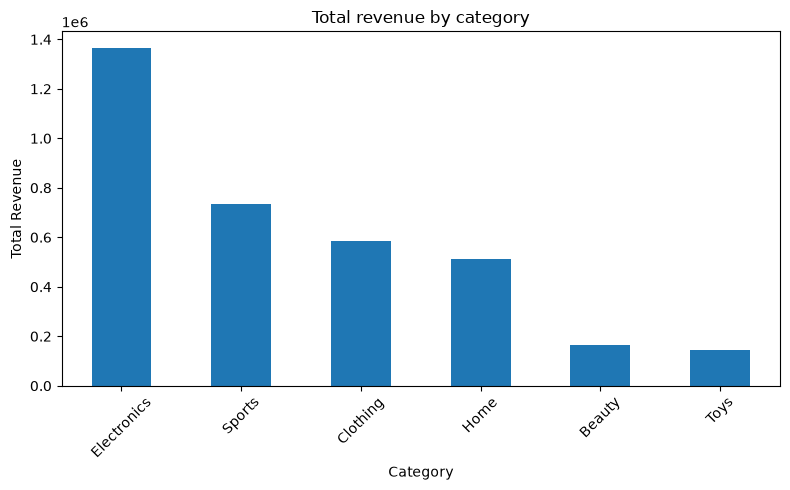

In [47]:
# Revenue by category _ Bar Chart
revenue_by_category.plot(kind="bar", figsize=(8, 5))

plt.title("Total revenue by category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [48]:
# Revenue by city 
revenue_by_city = df.groupby("city")["revenue"].sum()
revenue_by_city = revenue_by_city.sort_values(ascending=False)

print("Reneue by city")
display(revenue_by_city)


Reneue by city


city
Stockholm    1227201.94
Göteborg      859019.65
Malmö         567926.32
Uppsala       551478.42
Västerås      297140.90
Name: revenue, dtype: float64

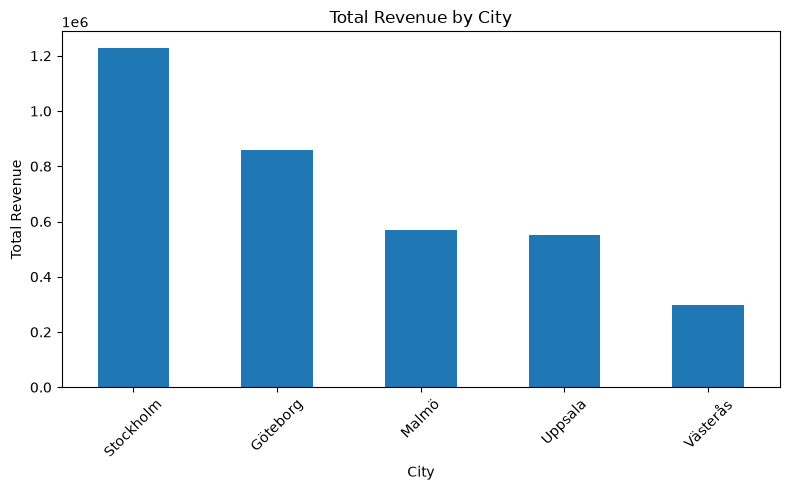

In [49]:
# Revenue by city _ Bar Chart
revenue_by_city.plot(kind="bar", figsize=(8, 5))

plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
# Top 3 categories by revenue
top_3_categories = revenue_by_category.head(3)

print("Top 3 categories by revenue: ")
display(top_3_categories)

Top 3 categories by revenue: 


category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64

In [51]:
# Custom function 1: calculate total revenue
def caculate_total_revenue(data):
    return data["revenue"].sum()

    #Custom function 2: calculateaverage order value 
def calculate_average_order_value(data):
    total_revenue = data["revenue"].sum()
    total_orders = data["order_id"].nunique()

    if total_orders == 0:
        return 0
    return total_revenue/total_orders

print("Total revenue: ", caculate_total_revenue(df))
print("Average order value: ", calculate_average_order_value(df))            


Total revenue:  3502767.2300000004
Average order value:  1401.1068920000002


In [52]:
# detect unusually high revenue

revenue_threshold = df["revenue"].mean() + 2 * df["revenue"].std()
high_revenue_orders = df[df["revenue"] > revenue_threshold]

print("Revenue threshold: ", revenue_threshold)
print("Number of unusually high revenue: ", len(high_revenue_orders))
display(high_revenue_orders.head())

Revenue threshold:  3734.9968268751745
Number of unusually high revenue:  121


,order_id,date,city,category,price,units,revenue
45,100045,2024-06-17,Västerås,Sports,1052.08,6,6312.48
53,100053,2024-05-18,Stockholm,Electronics,1033.02,4,4132.08
57,100057,2024-06-04,Malmö,Electronics,1393.58,3,4180.74
68,100068,2024-02-13,Göteborg,Electronics,1003.34,5,5016.70
72,100072,2024-02-26,Stockholm,Electronics,968.62,6,5811.72


## Business Insights
- Total revenue and total units sold summarize the overall business performance.
- Revenue by category helps identify the product catogories generating the most income.
- Revenue by city highlights the locations contributing the most to sales.
- The top three catogories can help guide inventory and marketing priorities.
- Unusually high revenue records should be reviewed to check whether they represent genuine large orders or possible data issues:

##Actionable Recommendations
1. Focus på marketing campaigns on the categories generating the highest revenue.
2. Review sales performance by city and consider tergetedpromotions in lower-revenue locations.
3. investigate unusually high-revenue records before making business decisionbased on them.

